In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
df = pd.read_csv('databasev4_2.csv')
X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])

Y = df['presence']

print(Y.value_counts())

presence
1    3782
0    1218
Name: count, dtype: int64


Random Forest Classifier

Acurácia: 0.927

Matriz de confusão:
[[206  38]
 [ 35 721]]

Relatório:
              precision    recall  f1-score   support

           0       0.85      0.84      0.85       244
           1       0.95      0.95      0.95       756

    accuracy                           0.93      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.93      0.93      0.93      1000



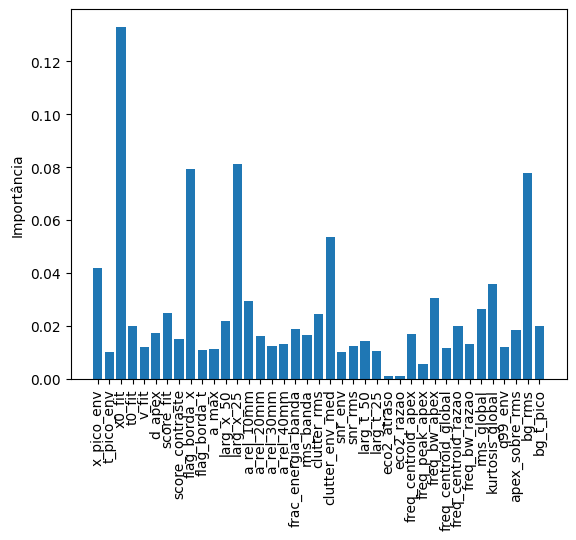

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

modelo = RandomForestClassifier(n_estimators=100,max_depth=None,random_state=42)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print("Acurácia:", accuracy_score(y_test,y_pred))
print("\nMatriz de confusão:")
print(confusion_matrix(y_test,y_pred))
print("\nRelatório:")
print(classification_report(y_test,y_pred))

nomes = ['x_pico_env', 't_pico_env', 'x0_fit', 't0_fit', 'v_fit', 'd_apex',
       'score_fit', 'score_contraste', 'flag_borda_x', 'flag_borda_t', 'a_max',
       'larg_x_50', 'larg_x_25', 'a_rel_10mm', 'a_rel_20mm', 'a_rel_30mm',
       'a_rel_40mm', 'frac_energia_banda', 'rms_banda', 'clutter_rms',
       'clutter_env_med', 'snr_env', 'snr_rms', 'larg_t_50', 'larg_t_25',
       'eco2_atraso', 'eco2_razao', 'freq_centroid_apex', 'freq_peak_apex',
       'freq_bw_apex', 'freq_centroid_global', 'freq_centroid_razao',
       'freq_bw_razao', 'rms_global', 'kurtosis_global', 'q99_env',
       'apex_sobre_rms', 'bg_rms', 'bg_t_pico']

imp = modelo.feature_importances_

plt.bar(nomes,imp)
plt.ylabel("Importância")
plt.xticks(rotation=90)
plt.show()

SVM